**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



**Set global variable**

In [2]:
## init: region folder
vec = c("fcc_astarr_macs_input_overlap", "fcc_astarr_macs_input_union")
names(vec) = vec

VEC_TXT_FOLDER = vec
for (txt in vec) {cat(txt, "\n")}

fcc_astarr_macs_input_overlap 
fcc_astarr_macs_input_union 


In [3]:
vec = c("CRISPR", "CRISPRi-HCRFF", "CRISPRi-Growth", "ENCODE-rE2G Benchmark")
names(vec) = vec
VEC_TXT_ASSAY_OUT = vec

vec = c("ASTARR", "WSTARR", "LMPRA", "TMPRA", "ATAC")
names(vec) = vec
VEC_TXT_ASSAY_INP = vec

**Check input files**

In [4]:
txt_folder = "fcc_astarr_macs_input_union"
txt_fdiry  = file.path(FD_RES, "analysis_fcc_correlation", txt_folder)
txt_fname  = "result.cripsr_vs_starrmpra.logit.stats.pool.*.tsv"
txt_fglob  = file.path(txt_fdiry, txt_fname)

vec = Sys.glob(txt_fglob)
for (txt in vec) {cat(txt, "\n")}

/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/analysis_fcc_correlation/fcc_astarr_macs_input_union/result.cripsr_vs_starrmpra.logit.stats.pool.distal.tsv 
/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/analysis_fcc_correlation/fcc_astarr_macs_input_union/result.cripsr_vs_starrmpra.logit.stats.pool.lrtest.tsv 
/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/analysis_fcc_correlation/fcc_astarr_macs_input_union/result.cripsr_vs_starrmpra.logit.stats.pool.proximal.tsv 


## Import data

In [5]:
### set directory
txt_foldr = "fcc_astarr_macs_input_union"
txt_fdiry = file.path(FD_RES, "analysis_fcc_correlation", txt_foldr)
txt_fname = "result.cripsr_vs_starrmpra.logit.stats.pool.lrtest.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

### read table
dat = read_tsv(txt_fpath, show_col_types = FALSE)

### assign and show
dat_logit_stats_pool_lrtest = dat
print(dim(dat))
fun_display_table(head(dat, 3))

[1]  4 16


Assay_STARRMPRA,Count,OR,OR_CI_Lower,OR_CI_Upper,Log10OR,Log10OR_CI_Lower,Log10OR_CI_Upper,LR_Stat,LR_Df,Pvalue,Padj,Delta_AIC,R2_McFadden_rel,R2_McFadden_rel_pct,LR_per_n
ASTARR,81233,1.333308,1.266701,1.403419,0.1249306,0.1026740,0.1471872,115.8338,1,0,0,-113.8338,0.0137363,1.37%,0.0014259
WSTARR,80454,1.463014,1.367135,1.565618,0.1652485,0.1358113,0.1946857,112.0444,1,0,0,-110.0444,0.0134413,1.34%,0.0013927
LMPRA,54295,1.523083,1.413717,1.640909,0.1827235,0.1503625,0.2150844,126.4721,1,0,0,-124.4721,0.0217349,2.17%,0.0023293


## Explore: result table

In [6]:
dat = dat_logit_stats_pool_lrtest
dat = dat %>% dplyr::arrange(desc(R2_McFadden_rel))
dat = dat %>% dplyr::transmute(
    Assay_STARRMPRA, 
    Count    = scales::comma(Count),
    OR       = format(OR, digits = 3, scientific = FALSE),
    LR_Stat  = round(LR_Stat, 3), 
    Df       = LR_Df,
    Pvalue   = format(Pvalue, digits = 3, scientific = TRUE),
    Padjust  = format(Padj,   digits = 3, scientific = TRUE),
    `R2 (Relative)` = R2_McFadden_rel_pct
)
fun_markdown_table(dat)



|Assay_STARRMPRA |Count  |OR    | LR_Stat| Df|Pvalue   |Padjust  |R2 (Relative) |
|:---------------|:------|:-----|-------:|--:|:--------|:--------|:-------------|
|LMPRA           |54,295 |1.523 | 126.472|  1|2.42e-29 |9.70e-29 |2.17%         |
|ASTARR          |81,233 |1.333 | 115.834|  1|5.17e-27 |1.03e-26 |1.37%         |
|WSTARR          |80,454 |1.463 | 112.044|  1|3.49e-26 |4.66e-26 |1.34%         |
|TMPRA           |1,053  |0.891 |   0.195|  1|6.59e-01 |6.59e-01 |0.13%         |

## Explore: plot odds ratio and relative R2

**Set plot text style**

In [7]:
THEME_TEXT = theme(
    title        = element_text(size = 16),
    axis.text.x  = element_text(size = 16),
    axis.text.y  = element_text(size = 16),
    axis.title.x = element_text(size = 16),
    axis.title.y = element_text(size = 16),
    legend.text  = element_text(size = 14),
    legend.title = element_text(size = 14) 
)

**Helper function**

In [8]:
fun_inner = function(num){
    if (num > 1000) {
        txt = round(num / 1000, 1)
        txt = paste0(txt, "k")
    } else {
        txt = as.character(num)
    }
    return(txt)
}

fun_wrapper = function(vec){
    vec = sapply(vec, fun_inner)
    return(vec)
}

**Generate plot for odds ratio**

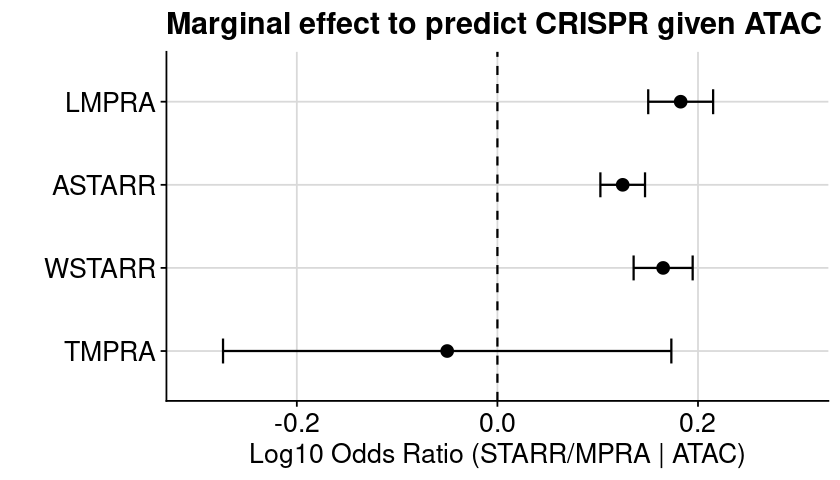

In [9]:
vec = c("STARRMPRA", VEC_TXT_ASSAY_INP)

dat = dat_logit_stats_pool_lrtest
dat = dat %>% 
    dplyr::mutate(Count_Label = fun_wrapper(Count)) %>%
    dplyr::mutate(Assay_Label = paste0(Assay_STARRMPRA, " (", Count_Label, ")"))
    #dplyr::mutate(Assay_STARRMPRA = factor(Assay_STARRMPRA, levels=vec)) %>%
    #dplyr::mutate(Assay_Label = factor(Assay_Label, levels=Assay_Label))

dat = dat %>% dplyr::arrange(desc(R2_McFadden_rel))

gpt = ggplot(dat, aes(x = Log10OR, y = reorder(Assay_STARRMPRA, R2_McFadden_rel))) +
    geom_point(size = 3) +
    geom_errorbar(aes(xmin = Log10OR_CI_Lower, xmax = Log10OR_CI_Upper), width = 0.3) +
    geom_vline(xintercept = 0, linetype="dashed") +
    labs(
        x = "Log10 Odds Ratio (STARR/MPRA | ATAC)", 
        y = "",
        title = "Marginal effect to predict CRISPR given ATAC") +
    theme_cowplot() +
    background_grid() +
    xlim(-0.3, 0.3) +
    THEME_TEXT

gpt_export_odds_ratio = gpt
options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

**Generate plot for relative R2**

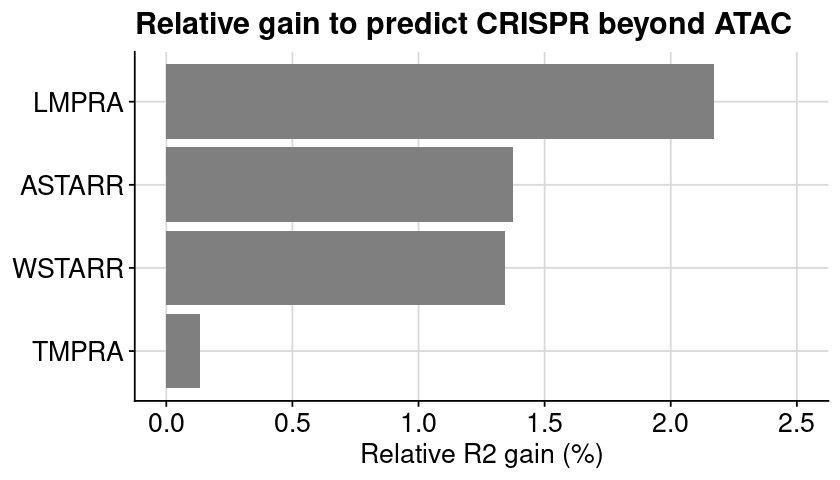

In [10]:
dat = dat_logit_stats_pool_lrtest
dat = dat %>% dplyr::arrange(desc(R2_McFadden_rel))

gpt = ggplot(dat, aes(y = reorder(Assay_STARRMPRA, R2_McFadden_rel), x = R2_McFadden_rel * 100)) +
    #geom_segment(aes(x = 0, xend = LR_per_n, yend = Assay_STARRMPRA), linewidth = 2, color = "grey50") +
    #geom_point(size = 2.6) +    
    geom_col(linewidth = 2, fill = "grey50") +
    labs(
        x = "Relative R2 gain (%)", 
        y = NULL,
        title = "Relative gain to predict CRISPR beyond ATAC"
    ) +
    theme_cowplot() +
    background_grid() +
    xlim(0, 2.5) +
    THEME_TEXT

gpt_export_relative_R2 = gpt
options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

## Explort figures

In [11]:
plt_export = gpt_export_relative_R2
txt_export = "fig.region_coverage_fcc.logit.marginal.pool.relative_r2"
num_height = 4
num_width  = 7

txt_fdiry = "./"
txt_fname = paste(txt_export, "png", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")

txt_fdiry = "./"
txt_fname = paste(txt_export, "svg", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")

In [12]:
plt_export = gpt_export_odds_ratio
txt_export = "fig.region_coverage_fcc.logit.marginal.pool.odds_ratio"
num_height = 4
num_width  = 7

txt_fdiry = "./"
txt_fname = paste(txt_export, "png", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")

txt_fdiry = "./"
txt_fname = paste(txt_export, "svg", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")